Scalable Airline Delay Prediction and Cloud Deployment Using Apache Spark and Machine Learning

###1.Project Overview

Airline delays are a major challenge in the aviation industry. They can affect passengers, airline operations, airport schedules and overall transportation efficiency. Understanding the factors associated with flight delays and developing reliable prediction models can help airlines make better operational decisions.

This project aims to develop a scalable data processing and machine learning pipeline for analysing and predicting airline flight delays using large-scale historical flight data.

Apache Spark will be used to process airline records efficiently, while machine learning algorithms will be developed using Spark MLlib to predict flight delays and estimate delay duration.

2. Problem Statement

Airline datasets contain millions of flight records with information about flight schedules, airlines, airports, routes and delays. Processing such large datasets using conventional data analysis techniques can become computationally expensive.

The project addresses two main problems:

How can large-scale airline flight data be efficiently processed and analysed using Apache Spark?

How effectively can machine learning models predict whether a flight will be delayed and estimate its delay duration?

3. Project Objectives

Explore and understand historical airline flight data.

Build a scalable data ingestion and preprocessing pipeline using PySpark.

Perform exploratory data analysis to identify flight delay patterns.

Develop classification models to predict flight delay status.

Develop regression models to estimate flight delay duration.

Evaluate model performance using appropriate metrics.

Investigate class imbalance and its effect on prediction performance.

Compare Spark and Pandas processing performance on a controlled dataset.

Develop a model-serving API and explore containerisation and cloud deployment.

4. Dataset

The project uses the Airline Delay Analysis dataset published by Kaggle user sherrytp.

The dataset contains yearly flight records from 2009 to 2019, along with an additional 2020 file. It includes information such as flight dates, airline identifiers, origin and destination airports, scheduled and actual flight times, arrival delays, departure delays and delay causes.

The initial modelling experiments will use the 2016–2018 records, subject to schema and data-quality validation. The remaining years will be considered for expansion.

Dataset source: Kaggle – Airline Delay Analysis

5. Technologies

Python

Apache Spark and PySpark

Spark MLlib

Pandas and NumPy

Matplotlib

Google Colab

Git and GitHub

FastAPI and Docker (deployment stage)

In [ ]:
!pip install -q pyspark==4.0.5

In [ ]:
import pyspark
print("PySpark installed:", pyspark.__version__)

PySpark installed: 4.0.5


In [ ]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("AirlineDelayPrediction")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")

print("Spark started successfully!")
print("Spark version:", spark.version)

Spark started successfully!
Spark version: 4.0.5


In [ ]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
from pyspark.sql.functions import round as spark_round

Check our project folder

In [ ]:

import os

drive_path = "/content/drive/MyDrive"

print("Folders in Google Drive:")
for item in os.listdir(drive_path):
    print(item)


Folders in Google Drive:
Colab Notebooks
Untitled document (1).gdoc
Untitled document.gdoc
Airline_Delay_Prediction


In [ ]:

import os

project_path = "/content/drive/MyDrive/Airline_Delay_Prediction"

print("PROJECT FOLDER CONTENTS")
print("-" * 40)

for item in os.listdir(project_path):
    print(item)


PROJECT FOLDER CONTENTS
----------------------------------------
data
notebooks
src
models
results
deployment
tests
reports
docs
README.md


Check the dataset folder

In [ ]:

import os

data_path = os.path.join(project_path, "data")

for root, dirs, files in os.walk(data_path):
    level = root.replace(data_path, "").count(os.sep)
    indent = "  " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}  {file}")


data/
  raw/
    20.csv
    2009.csv
    2010.csv
    2011.csv
    2012.csv
    2013.csv
    2014.csv
    2015.csv
    2016.csv
    2017.csv
    2018.csv
    2019.csv
  processed/
    airline_2016_2018/
      part-00001-2750fdbf-6d6b-4bb4-9651-3d31d1713a14-c000.snappy.parquet
      part-00000-2750fdbf-6d6b-4bb4-9651-3d31d1713a14-c000.snappy.parquet
      .part-00001-2750fdbf-6d6b-4bb4-9651-3d31d1713a14-c000.snappy.parquet.crc
      .part-00000-2750fdbf-6d6b-4bb4-9651-3d31d1713a14-c000.snappy.parquet.crc
      part-00002-2750fdbf-6d6b-4bb4-9651-3d31d1713a14-c000.snappy.parquet
      part-00003-2750fdbf-6d6b-4bb4-9651-3d31d1713a14-c000.snappy.parquet
      .part-00002-2750fdbf-6d6b-4bb4-9651-3d31d1713a14-c000.snappy.parquet.crc
      .part-00003-2750fdbf-6d6b-4bb4-9651-3d31d1713a14-c000.snappy.parquet.crc
      part-00004-2750fdbf-6d6b-4bb4-9651-3d31d1713a14-c000.snappy.parquet
      .part-00004-2750fdbf-6d6b-4bb4-9651-3d31d1713a14-c000.snappy.parquet.crc
      part-00005-2750fdbf-6d6b-4

Verify our modelling files

In [ ]:

import os

raw_path = os.path.join(project_path, "data", "raw")

selected_years = [2016, 2017, 2018]

print("INITIAL MODELLING DATASET")
print("-" * 45)

for year in selected_years:
    file_path = os.path.join(raw_path, f"{year}.csv")

    if os.path.exists(file_path):
        size_gb = os.path.getsize(file_path) / (1024 ** 3)
        print(f"{year}: Available | {size_gb:.2f} GB")
    else:
        print(f"{year}: File not found")


INITIAL MODELLING DATASET
---------------------------------------------
2016: Available | 0.65 GB
2017: Available | 0.65 GB
2018: Available | 0.83 GB


Understand the dataset columns

In [ ]:

import csv
import os

print("COLUMN STRUCTURE OF SELECTED YEARS")
print("=" * 60)

for year in [2016, 2017, 2018]:

    file_path = os.path.join(raw_path, f"{year}.csv")

    with open(file_path, "r", encoding="utf-8-sig") as file:
        reader = csv.reader(file)
        columns = next(reader)

    print(f"\nYEAR: {year}")
    print("Number of columns:", len(columns))
    print("Column names:")
    print(columns)


COLUMN STRUCTURE OF SELECTED YEARS

YEAR: 2016
Number of columns: 28
Column names:
['FL_DATE', 'OP_CARRIER', 'OP_CARRIER_FL_NUM', 'ORIGIN', 'DEST', 'CRS_DEP_TIME', 'DEP_TIME', 'DEP_DELAY', 'TAXI_OUT', 'WHEELS_OFF', 'WHEELS_ON', 'TAXI_IN', 'CRS_ARR_TIME', 'ARR_TIME', 'ARR_DELAY', 'CANCELLED', 'CANCELLATION_CODE', 'DIVERTED', 'CRS_ELAPSED_TIME', 'ACTUAL_ELAPSED_TIME', 'AIR_TIME', 'DISTANCE', 'CARRIER_DELAY', 'WEATHER_DELAY', 'NAS_DELAY', 'SECURITY_DELAY', 'LATE_AIRCRAFT_DELAY', 'Unnamed: 27']

YEAR: 2017
Number of columns: 28
Column names:
['FL_DATE', 'OP_CARRIER', 'OP_CARRIER_FL_NUM', 'ORIGIN', 'DEST', 'CRS_DEP_TIME', 'DEP_TIME', 'DEP_DELAY', 'TAXI_OUT', 'WHEELS_OFF', 'WHEELS_ON', 'TAXI_IN', 'CRS_ARR_TIME', 'ARR_TIME', 'ARR_DELAY', 'CANCELLED', 'CANCELLATION_CODE', 'DIVERTED', 'CRS_ELAPSED_TIME', 'ACTUAL_ELAPSED_TIME', 'AIR_TIME', 'DISTANCE', 'CARRIER_DELAY', 'WEATHER_DELAY', 'NAS_DELAY', 'SECURITY_DELAY', 'LATE_AIRCRAFT_DELAY', 'Unnamed: 27']

YEAR: 2018
Number of columns: 28
Column na

Check the extra column

In [ ]:

import csv
import os

print("Checking Unnamed: 27 in selected years")
print("=" * 45)

for year in [2016, 2017, 2018]:

    file_path = os.path.join(raw_path, f"{year}.csv")

    with open(file_path, "r", encoding="utf-8-sig") as file:
        reader = csv.DictReader(file)

        non_empty_count = 0
        checked_count = 0

        for row in reader:
            checked_count += 1

            value = row.get("Unnamed: 27", "")

            if value and value.strip():
                non_empty_count += 1

    print(f"\nYear: {year}")
    print("Records checked:", checked_count)
    print("Non-empty extra-column values:", non_empty_count)


Checking Unnamed: 27 in selected years

Year: 2016
Records checked: 5617658
Non-empty extra-column values: 0

Year: 2017
Records checked: 5674621
Non-empty extra-column values: 0

Year: 2018
Records checked: 7213446
Non-empty extra-column values: 0


Create our Spark session

In [ ]:

# Import Spark
from pyspark.sql import SparkSession

# Create Spark session
spark = (
    SparkSession.builder
    .appName("AirlineDelayPrediction")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

# Reduce unnecessary log messages
spark.sparkContext.setLogLevel("WARN")

print("Spark session created successfully!")
print("Spark version:", spark.version)


Spark session created successfully!
Spark version: 4.0.5


Load the 2016 dataset

In [ ]:

# Path to the 2016 airline dataset
file_2016 = os.path.join(raw_path, "2016.csv")

# Load the CSV using Spark
df_2016 = (
    spark.read
    .option("header", "true")
    .option("inferSchema", "true")
    .option("mode", "FAILFAST")
    .csv(file_2016)
)

# Remove the verified empty column
df_2016 = df_2016.drop("Unnamed: 27")

print("2016 dataset loaded successfully!")
print("Number of columns:", len(df_2016.columns))

# Display the column structure
df_2016.printSchema()


2016 dataset loaded successfully!
Number of columns: 27
root
 |-- FL_DATE: date (nullable = true)
 |-- OP_CARRIER: string (nullable = true)
 |-- OP_CARRIER_FL_NUM: integer (nullable = true)
 |-- ORIGIN: string (nullable = true)
 |-- DEST: string (nullable = true)
 |-- CRS_DEP_TIME: integer (nullable = true)
 |-- DEP_TIME: double (nullable = true)
 |-- DEP_DELAY: double (nullable = true)
 |-- TAXI_OUT: double (nullable = true)
 |-- WHEELS_OFF: double (nullable = true)
 |-- WHEELS_ON: double (nullable = true)
 |-- TAXI_IN: double (nullable = true)
 |-- CRS_ARR_TIME: integer (nullable = true)
 |-- ARR_TIME: double (nullable = true)
 |-- ARR_DELAY: double (nullable = true)
 |-- CANCELLED: double (nullable = true)
 |-- CANCELLATION_CODE: string (nullable = true)
 |-- DIVERTED: double (nullable = true)
 |-- CRS_ELAPSED_TIME: double (nullable = true)
 |-- ACTUAL_ELAPSED_TIME: double (nullable = true)
 |-- AIR_TIME: double (nullable = true)
 |-- DISTANCE: double (nullable = true)
 |-- CARRIER_

Check the number of records

In [ ]:

# Count the records in the 2016 dataset

total_records_2016 = df_2016.count()

print("2016 DATASET SUMMARY")
print("-" * 35)
print("Total flight records:", f"{total_records_2016:,}")
print("Total columns:", len(df_2016.columns))


2016 DATASET SUMMARY
-----------------------------------
Total flight records: 5,617,658
Total columns: 27


Check the date range

In [ ]:
from pyspark.sql.functions import min, max

df_2016.select(
    min("FL_DATE").alias("First Flight Date"),
    max("FL_DATE").alias("Last Flight Date")
).show()

+-----------------+----------------+
|First Flight Date|Last Flight Date|
+-----------------+----------------+
|       2016-01-01|      2016-12-31|
+-----------------+----------------+



Load the 2017 dataset

In [ ]:
# Load the 2017 airline dataset

file_2017 = os.path.join(raw_path, "2017.csv")

df_2017 = (
    spark.read
    .option("header", "true")
    .option("inferSchema", "true")
    .option("mode", "FAILFAST")
    .csv(file_2017)
)

# Remove the verified empty column
df_2017 = df_2017.drop("Unnamed: 27")

print("2017 dataset loaded successfully!")
print("Number of columns:", len(df_2017.columns))

df_2017.printSchema()

2017 dataset loaded successfully!
Number of columns: 27
root
 |-- FL_DATE: date (nullable = true)
 |-- OP_CARRIER: string (nullable = true)
 |-- OP_CARRIER_FL_NUM: integer (nullable = true)
 |-- ORIGIN: string (nullable = true)
 |-- DEST: string (nullable = true)
 |-- CRS_DEP_TIME: integer (nullable = true)
 |-- DEP_TIME: double (nullable = true)
 |-- DEP_DELAY: double (nullable = true)
 |-- TAXI_OUT: double (nullable = true)
 |-- WHEELS_OFF: double (nullable = true)
 |-- WHEELS_ON: double (nullable = true)
 |-- TAXI_IN: double (nullable = true)
 |-- CRS_ARR_TIME: integer (nullable = true)
 |-- ARR_TIME: double (nullable = true)
 |-- ARR_DELAY: double (nullable = true)
 |-- CANCELLED: double (nullable = true)
 |-- CANCELLATION_CODE: string (nullable = true)
 |-- DIVERTED: double (nullable = true)
 |-- CRS_ELAPSED_TIME: double (nullable = true)
 |-- ACTUAL_ELAPSED_TIME: double (nullable = true)
 |-- AIR_TIME: double (nullable = true)
 |-- DISTANCE: double (nullable = true)
 |-- CARRIER_

Load the 2018 dataset

In [ ]:
# Load the 2018 airline dataset

file_2018 = os.path.join(raw_path, "2018.csv")

df_2018 = (
    spark.read
    .option("header", "true")
    .option("inferSchema", "true")
    .option("mode", "FAILFAST")
    .csv(file_2018)
)

# Remove the verified empty column
df_2018 = df_2018.drop("Unnamed: 27")

print("2018 dataset loaded successfully!")
print("Number of columns:", len(df_2018.columns))

df_2018.printSchema()

2018 dataset loaded successfully!
Number of columns: 27
root
 |-- FL_DATE: date (nullable = true)
 |-- OP_CARRIER: string (nullable = true)
 |-- OP_CARRIER_FL_NUM: integer (nullable = true)
 |-- ORIGIN: string (nullable = true)
 |-- DEST: string (nullable = true)
 |-- CRS_DEP_TIME: integer (nullable = true)
 |-- DEP_TIME: double (nullable = true)
 |-- DEP_DELAY: double (nullable = true)
 |-- TAXI_OUT: double (nullable = true)
 |-- WHEELS_OFF: double (nullable = true)
 |-- WHEELS_ON: double (nullable = true)
 |-- TAXI_IN: double (nullable = true)
 |-- CRS_ARR_TIME: integer (nullable = true)
 |-- ARR_TIME: double (nullable = true)
 |-- ARR_DELAY: double (nullable = true)
 |-- CANCELLED: double (nullable = true)
 |-- CANCELLATION_CODE: string (nullable = true)
 |-- DIVERTED: double (nullable = true)
 |-- CRS_ELAPSED_TIME: double (nullable = true)
 |-- ACTUAL_ELAPSED_TIME: double (nullable = true)
 |-- AIR_TIME: double (nullable = true)
 |-- DISTANCE: double (nullable = true)
 |-- CARRIER_

Verify the 2018 record count and date range

In [ ]:
from pyspark.sql.functions import min, max

print("2018 DATASET SUMMARY")
print("-" * 35)

print("Total records:", f"{df_2018.count():,}")

df_2018.select(
    min("FL_DATE").alias("First Flight Date"),
    max("FL_DATE").alias("Last Flight Date")
).show()

2018 DATASET SUMMARY
-----------------------------------
Total records: 7,213,446
+-----------------+----------------+
|First Flight Date|Last Flight Date|
+-----------------+----------------+
|       2018-01-01|      2018-12-31|
+-----------------+----------------+



Compare schemas before combining

In [ ]:
# Compare the schemas of all three yearly datasets

schema_2016 = [(field.name, field.dataType) for field in df_2016.schema.fields]
schema_2017 = [(field.name, field.dataType) for field in df_2017.schema.fields]
schema_2018 = [(field.name, field.dataType) for field in df_2018.schema.fields]

print("2016 and 2017 schemas match:", schema_2016 == schema_2017)
print("2017 and 2018 schemas match:", schema_2017 == schema_2018)
print("2016 and 2018 schemas match:", schema_2016 == schema_2018)

2016 and 2017 schemas match: True
2017 and 2018 schemas match: True
2016 and 2018 schemas match: True


Combine 2016, 2017 and 2018

In [ ]:
# Combine the three yearly datasets

df_combined = (
    df_2016
    .unionByName(df_2017)
    .unionByName(df_2018)
)

print("Combined dataset created successfully!")
print("Total columns:", len(df_combined.columns))

print("\nCombined dataset schema:")
df_combined.printSchema()

Combined dataset created successfully!
Total columns: 27

Combined dataset schema:
root
 |-- FL_DATE: date (nullable = true)
 |-- OP_CARRIER: string (nullable = true)
 |-- OP_CARRIER_FL_NUM: integer (nullable = true)
 |-- ORIGIN: string (nullable = true)
 |-- DEST: string (nullable = true)
 |-- CRS_DEP_TIME: integer (nullable = true)
 |-- DEP_TIME: double (nullable = true)
 |-- DEP_DELAY: double (nullable = true)
 |-- TAXI_OUT: double (nullable = true)
 |-- WHEELS_OFF: double (nullable = true)
 |-- WHEELS_ON: double (nullable = true)
 |-- TAXI_IN: double (nullable = true)
 |-- CRS_ARR_TIME: integer (nullable = true)
 |-- ARR_TIME: double (nullable = true)
 |-- ARR_DELAY: double (nullable = true)
 |-- CANCELLED: double (nullable = true)
 |-- CANCELLATION_CODE: string (nullable = true)
 |-- DIVERTED: double (nullable = true)
 |-- CRS_ELAPSED_TIME: double (nullable = true)
 |-- ACTUAL_ELAPSED_TIME: double (nullable = true)
 |-- AIR_TIME: double (nullable = true)
 |-- DISTANCE: double (nul

Verify the combined dataset

In [ ]:
# Verify the combined dataset

combined_count = df_combined.count()

expected_count = (
    5617658 +
    5674621 +
    7213446
)

print("COMBINED DATASET VALIDATION")
print("-" * 40)

print("Expected records:", f"{expected_count:,}")
print("Actual records:  ", f"{combined_count:,}")
print("Total columns:   ", len(df_combined.columns))

print(
    "Validation:",
    "PASSED" if combined_count == expected_count else "FAILED"
)

COMBINED DATASET VALIDATION
----------------------------------------
Expected records: 18,505,725
Actual records:   18,505,725
Total columns:    27
Validation: PASSED


Save the combined dataset

In [ ]:
# Define the processed data output path

processed_path = os.path.join(
    project_path,
    "data",
    "processed",
    "airline_2016_2018"
)

# Save the combined dataset in Parquet format

df_combined.write \
    .mode("overwrite") \
    .parquet(processed_path)

print("Combined dataset saved successfully!")
print("Saved location:", processed_path)

Combined dataset saved successfully!
Saved location: /content/drive/MyDrive/Airline_Delay_Prediction/data/processed/airline_2016_2018


Verify the saved Parquet dataset

In [ ]:
# Read the saved Parquet dataset

df_saved = spark.read.parquet(processed_path)

# Verify the saved dataset

saved_count = df_saved.count()

print("SAVED DATASET VALIDATION")
print("-" * 40)
print("Records:", f"{saved_count:,}")
print("Columns:", len(df_saved.columns))

print(
    "Validation:",
    "PASSED" if saved_count == 18505725 else "FAILED"
)

SAVED DATASET VALIDATION
----------------------------------------
Records: 18,505,725
Columns: 27
Validation: PASSED


Analyse missing values

### 4. Data Quality Analysis

Data quality analysis is performed to understand the completeness and reliability of the airline dataset before preprocessing and model development.

The first step is to identify missing values in each column. Both the number and percentage of missing values are calculated to understand the extent of missing data and determine appropriate preprocessing strategies.

In [ ]:

from pyspark.sql.functions import col, sum, when, isnan
from pyspark.sql.types import FloatType, DoubleType

# Identify columns that support NaN checking
numeric_float_columns = [
    field.name
    for field in df_saved.schema.fields
    if isinstance(field.dataType, (FloatType, DoubleType))
]

# Calculate missing values for every column
missing_summary = df_saved.select([
    sum(
        when(
            col(c).isNull() |
            (isnan(col(c)) if c in numeric_float_columns else when(col(c).isNull(), False)),
            1
        ).otherwise(0)
    ).alias(c)
    for c in df_saved.columns
])

# Collect the summary
missing_rows = missing_summary.collect()[0]

# Calculate missing counts and percentages
missing_data = []

for column_name in df_saved.columns:
    missing_count = missing_rows[column_name]
    missing_percentage = (missing_count / saved_count) * 100

    missing_data.append(
        (column_name, missing_count, round(missing_percentage, 2))
    )

# Display results
missing_df = spark.createDataFrame(
    missing_data,
    ["Column", "Missing_Count", "Missing_Percentage"]
)

missing_df.orderBy(
    col("Missing_Count").desc()
).show(27, truncate=False)


+-------------------+-------------+------------------+
|Column             |Missing_Count|Missing_Percentage|
+-------------------+-------------+------------------+
|CANCELLATION_CODE  |18240587     |98.57             |
|CARRIER_DELAY      |15159303     |81.92             |
|WEATHER_DELAY      |15159303     |81.92             |
|NAS_DELAY          |15159303     |81.92             |
|SECURITY_DELAY     |15159303     |81.92             |
|LATE_AIRCRAFT_DELAY|15159303     |81.92             |
|ARR_DELAY          |311764       |1.68              |
|ACTUAL_ELAPSED_TIME|309166       |1.67              |
|AIR_TIME           |309166       |1.67              |
|WHEELS_ON          |271764       |1.47              |
|TAXI_IN            |271764       |1.47              |
|ARR_TIME           |271763       |1.47              |
|TAXI_OUT           |263393       |1.42              |
|WHEELS_OFF         |263388       |1.42              |
|DEP_DELAY          |261033       |1.41              |
|DEP_TIME 

Investigate cancelled and diverted flight

### 4.1 Flight Status Analysis

Missing arrival and operational information may be associated with cancelled or diverted flights. Therefore, cancelled, diverted and normally operated flights are examined separately before deciding how to handle missing values.

This investigation helps distinguish structurally missing values from potentially incomplete records.

In [ ]:
from pyspark.sql.functions import col, count, sum, when

# Examine flight status

flight_status = df_saved.groupBy(
    "CANCELLED",
    "DIVERTED"
).agg(
    count("*").alias("Total_Flights"),
    sum(
        when(col("ARR_DELAY").isNull(), 1).otherwise(0)
    ).alias("Missing_Arrival_Delay")
).orderBy(
    "CANCELLED",
    "DIVERTED"
)

flight_status.show(truncate=False)

+---------+--------+-------------+---------------------+
|CANCELLED|DIVERTED|Total_Flights|Missing_Arrival_Delay|
+---------+--------+-------------+---------------------+
|0.0      |0.0     |18196561     |2600                 |
|0.0      |1.0     |44026        |44026                |
|1.0      |0.0     |265123       |265123               |
|1.0      |1.0     |15           |15                   |
+---------+--------+-------------+---------------------+



Flight status analysis

Calculate the flight-status proportions

In [ ]:
from pyspark.sql.functions import count, round

flight_status_summary = df_saved.groupBy(
    "CANCELLED",
    "DIVERTED"
).agg(
    count("*").alias("Total_Flights")
).withColumn(
    "Percentage",
    round(
        col("Total_Flights") / saved_count * 100,
        2
    )
).orderBy(
    col("Total_Flights").desc()
)

flight_status_summary.show()

+---------+--------+-------------+----------+
|CANCELLED|DIVERTED|Total_Flights|Percentage|
+---------+--------+-------------+----------+
|      0.0|     0.0|     18196561|     98.33|
|      1.0|     0.0|       265123|      1.43|
|      0.0|     1.0|        44026|      0.24|
|      1.0|     1.0|           15|       0.0|
+---------+--------+-------------+----------+



Investigate the 2,600 missing arrival delays

In [ ]:
# Inspect normally operated flights with missing arrival delay

normal_missing_arrival = df_saved.filter(
    (col("CANCELLED") == 0) &
    (col("DIVERTED") == 0) &
    (col("ARR_DELAY").isNull())
)

print("Records with missing arrival delay:", normal_missing_arrival.count())

normal_missing_arrival.select(
    "FL_DATE",
    "OP_CARRIER",
    "ORIGIN",
    "DEST",
    "DEP_TIME",
    "DEP_DELAY",
    "ARR_TIME",
    "ARR_DELAY",
    "ACTUAL_ELAPSED_TIME",
    "AIR_TIME"
).show(10, truncate=False)

Records with missing arrival delay: 2600
+----------+----------+------+----+--------+---------+--------+---------+-------------------+--------+
|FL_DATE   |OP_CARRIER|ORIGIN|DEST|DEP_TIME|DEP_DELAY|ARR_TIME|ARR_DELAY|ACTUAL_ELAPSED_TIME|AIR_TIME|
+----------+----------+------+----+--------+---------+--------+---------+-------------------+--------+
|2018-06-17|9E        |CHO   |ATL |1557.0  |-3.0     |1743.0  |NULL     |106.0              |76.0    |
|2018-06-17|9E        |MSP   |DSM |1540.0  |7.0      |1648.0  |NULL     |68.0               |41.0    |
|2018-06-18|9E        |ORF   |LGA |1535.0  |NULL     |1712.0  |NULL     |97.0               |59.0    |
|2018-06-18|9E        |BUF   |LGA |805.0   |-10.0    |946.0   |NULL     |101.0              |52.0    |
|2018-06-18|9E        |RDU   |IND |1006.0  |7.0      |1148.0  |NULL     |102.0              |72.0    |
|2018-06-18|9E        |DTW   |GSO |1527.0  |-3.0     |1710.0  |NULL     |103.0              |69.0    |
|2018-06-18|9E        |MVY   |LG

Check whether the 2,600 records are concentrated in particular years

In [ ]:
from pyspark.sql.functions import year, count

# Count missing arrival delays by year
missing_arrival_by_year = (
    normal_missing_arrival
    .groupBy(year("FL_DATE").alias("Year"))
    .agg(count("*").alias("Missing_Arrival_Records"))
    .orderBy("Year")
)

missing_arrival_by_year.show()

+----+-----------------------+
|Year|Missing_Arrival_Records|
+----+-----------------------+
|2017|                      1|
|2018|                   2599|
+----+-----------------------+



Check the monthly distribution in 2018

In [ ]:
from pyspark.sql.functions import month, count

missing_arrival_by_month = (
    normal_missing_arrival
    .filter(year("FL_DATE") == 2018)
    .groupBy(month("FL_DATE").alias("Month"))
    .agg(
        count("*").alias("Missing_ARR_DELAY")
    )
    .orderBy("Month")
)

missing_arrival_by_month.show(12)

+-----+-----------------+
|Month|Missing_ARR_DELAY|
+-----+-----------------+
|    1|              202|
|    2|              229|
|    3|              373|
|    4|              346|
|    5|              350|
|    6|              391|
|    7|              375|
|    8|              333|
+-----+-----------------+



Interpret the monthly pattern

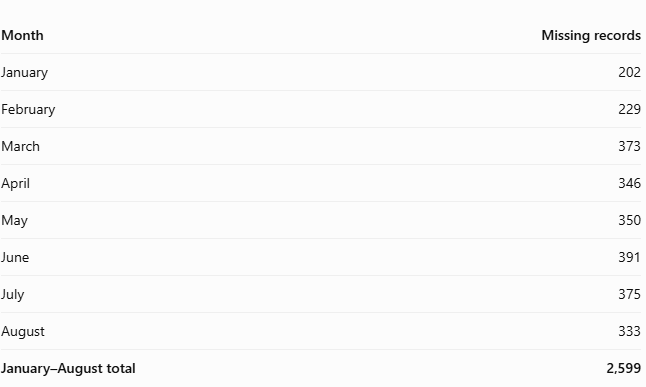

Check the remaining months

In [ ]:
from pyspark.sql.functions import month, count

# Count missing arrival delays by month in 2018
missing_arrival_by_month = (
    normal_missing_arrival
    .filter(year("FL_DATE") == 2018)
    .groupBy(month("FL_DATE").alias("Month"))
    .agg(count("*").alias("Missing_ARR_DELAY"))
)

# Generate months 1 to 12 correctly
all_months = spark.range(0, 12).selectExpr(
    "CAST(id AS INT) + 1 AS Month"
)

# Include months with zero missing records
complete_monthly_summary = (
    all_months
    .join(missing_arrival_by_month, "Month", "left")
    .fillna(0, subset=["Missing_ARR_DELAY"])
    .orderBy("Month")
)

complete_monthly_summary.show(12)

+-----+-----------------+
|Month|Missing_ARR_DELAY|
+-----+-----------------+
|    1|              202|
|    2|              229|
|    3|              373|
|    4|              346|
|    5|              350|
|    6|              391|
|    7|              375|
|    8|              333|
|    9|                0|
|   10|                0|
|   11|                0|
|   12|                0|
+-----+-----------------+



### 4.2 Investigation of Missing Arrival Delays

The dataset contains 2,600 normally operated flights with missing arrival-delay values. A year-wise investigation revealed that one record belongs to 2017, while the remaining 2,599 records belong to 2018.

Further monthly analysis showed that all 2,599 missing records in 2018 occurred between January and August. No missing arrival-delay values were observed from September to December among normally operated flights.

This indicates a time-specific data-quality pattern in the 2018 records. The underlying cause has not yet been established.

**Preliminary handling decision:** These records will not be assigned artificial arrival-delay values. Since arrival delay is the prediction target, records without a valid target will be excluded from supervised model training, subject to the final flight-status filtering procedure.

Check other missing values in those 2,600 records

In [ ]:
from pyspark.sql.functions import col, sum, when

# Check missing values in the 2,600 affected records

columns_to_check = [
    "DEP_TIME",
    "DEP_DELAY",
    "ARR_TIME",
    "ARR_DELAY",
    "ACTUAL_ELAPSED_TIME",
    "AIR_TIME",
    "TAXI_OUT",
    "TAXI_IN",
    "WHEELS_OFF",
    "WHEELS_ON"
]

normal_missing_arrival.select([
    sum(
        when(col(c).isNull(), 1).otherwise(0)
    ).alias(c)
    for c in columns_to_check
]).show(truncate=False)

+--------+---------+--------+---------+-------------------+--------+--------+-------+----------+---------+
|DEP_TIME|DEP_DELAY|ARR_TIME|ARR_DELAY|ACTUAL_ELAPSED_TIME|AIR_TIME|TAXI_OUT|TAXI_IN|WHEELS_OFF|WHEELS_ON|
+--------+---------+--------+---------+-------------------+--------+--------+-------+----------+---------+
|0       |137      |1       |2600     |1                  |1       |0       |1      |0         |1        |
+--------+---------+--------+---------+-------------------+--------+--------+-------+----------+---------+



Interpret the findings

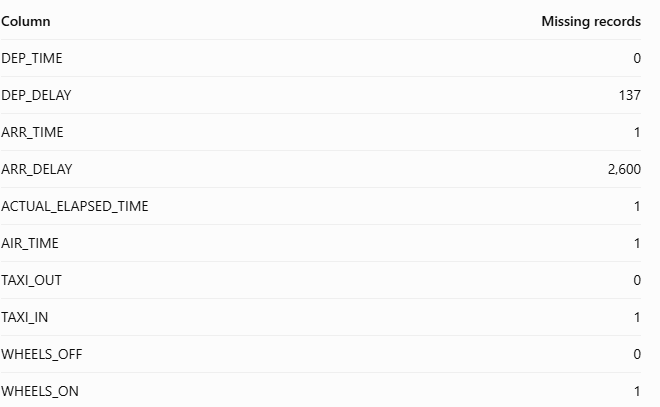

Check the missing departure-delay records

In [ ]:
# Find records with missing departure delay
missing_departure_delay = normal_missing_arrival.filter(
    col("DEP_DELAY").isNull()
)

print(
    "Records with missing departure delay:",
    missing_departure_delay.count()
)

missing_departure_delay.select(
    "FL_DATE",
    "OP_CARRIER",
    "ORIGIN",
    "DEST",
    "DEP_TIME",
    "ARR_TIME",
    "ACTUAL_ELAPSED_TIME",
    "AIR_TIME"
).show(10, truncate=False)

Records with missing departure delay: 137
+----------+----------+------+----+--------+--------+-------------------+--------+
|FL_DATE   |OP_CARRIER|ORIGIN|DEST|DEP_TIME|ARR_TIME|ACTUAL_ELAPSED_TIME|AIR_TIME|
+----------+----------+------+----+--------+--------+-------------------+--------+
|2018-06-18|9E        |ORF   |LGA |1535.0  |1712.0  |97.0               |59.0    |
|2018-06-18|9E        |MVY   |LGA |1158.0  |1315.0  |77.0               |46.0    |
|2018-06-18|9E        |EVV   |ATL |1030.0  |1305.0  |95.0               |60.0    |
|2018-06-19|9E        |ATL   |CID |921.0   |1025.0  |124.0              |101.0   |
|2018-06-20|9E        |CVG   |LGA |700.0   |900.0   |120.0              |88.0    |
|2018-06-22|9E        |CVG   |BOS |720.0   |926.0   |126.0              |105.0   |
|2018-06-22|9E        |LGA   |CVG |1010.0  |1234.0  |144.0              |92.0    |
|2018-06-23|9E        |MSP   |STL |1504.0  |1639.0  |95.0               |64.0    |
|2018-06-24|9E        |ORF   |DTW |1510.0  |1

Check the airline distribution

In [ ]:
from pyspark.sql.functions import col, count

missing_departure_delay.groupBy(
    "OP_CARRIER"
).agg(
    count("*").alias("Missing_DEP_DELAY_Records")
).orderBy(
    col("Missing_DEP_DELAY_Records").desc()
).show(truncate=False)

+----------+-------------------------+
|OP_CARRIER|Missing_DEP_DELAY_Records|
+----------+-------------------------+
|9E        |137                      |
+----------+-------------------------+



Check the dates of these 137 records

In [ ]:
from pyspark.sql.functions import min, max, countDistinct

missing_departure_delay.select(
    min("FL_DATE").alias("First_Date"),
    max("FL_DATE").alias("Last_Date"),
    countDistinct("FL_DATE").alias("Number_of_Affected_Days")
).show()

+----------+----------+-----------------------+
|First_Date| Last_Date|Number_of_Affected_Days|
+----------+----------+-----------------------+
|2018-01-01|2018-08-30|                    107|
+----------+----------+-----------------------+



Check the monthly distribution of the 137 records

In [ ]:
from pyspark.sql.functions import month, count

missing_dep_by_month = (
    missing_departure_delay
    .groupBy(month("FL_DATE").alias("Month"))
    .agg(
        count("*").alias("Missing_DEP_DELAY")
    )
    .orderBy("Month")
)

missing_dep_by_month.show(12)

+-----+-----------------+
|Month|Missing_DEP_DELAY|
+-----+-----------------+
|    1|               13|
|    2|                9|
|    3|               24|
|    4|               17|
|    5|               17|
|    6|               24|
|    7|               24|
|    8|                9|
+-----+-----------------+



Interpret the monthly distribution

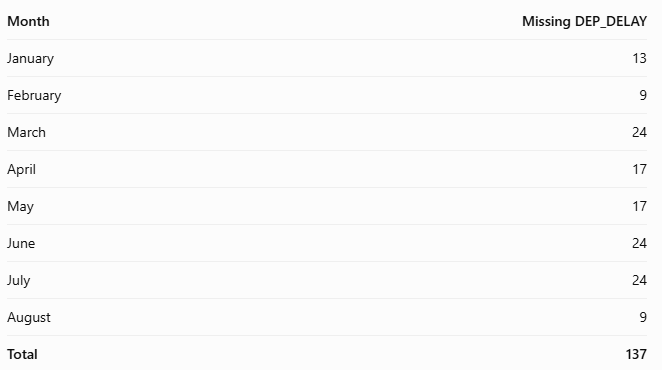

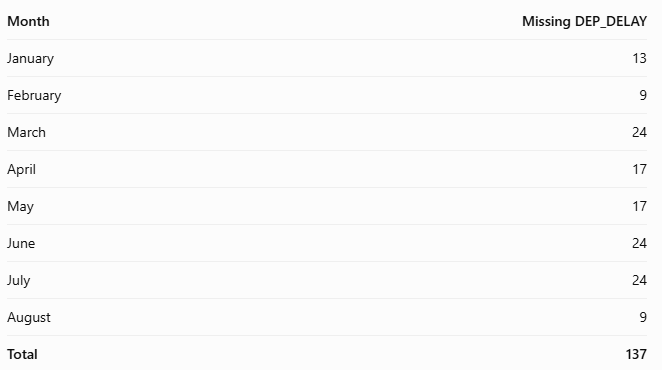

Check duplicate records

In [ ]:
from pyspark.sql.functions import count

duplicate_groups = (
    df_saved
    .groupBy(df_saved.columns)
    .agg(count("*").alias("frequency"))
    .filter("frequency > 1")
)

duplicate_groups.show(10, truncate=False)

+-------+----------+-----------------+------+----+------------+--------+---------+--------+----------+---------+-------+------------+--------+---------+---------+-----------------+--------+----------------+-------------------+--------+--------+-------------+-------------+---------+--------------+-------------------+---------+
|FL_DATE|OP_CARRIER|OP_CARRIER_FL_NUM|ORIGIN|DEST|CRS_DEP_TIME|DEP_TIME|DEP_DELAY|TAXI_OUT|WHEELS_OFF|WHEELS_ON|TAXI_IN|CRS_ARR_TIME|ARR_TIME|ARR_DELAY|CANCELLED|CANCELLATION_CODE|DIVERTED|CRS_ELAPSED_TIME|ACTUAL_ELAPSED_TIME|AIR_TIME|DISTANCE|CARRIER_DELAY|WEATHER_DELAY|NAS_DELAY|SECURITY_DELAY|LATE_AIRCRAFT_DELAY|frequency|
+-------+----------+-----------------+------+----+------------+--------+---------+--------+----------+---------+-------+------------+--------+---------+---------+-----------------+--------+----------------+-------------------+--------+--------+-------------+-------------+---------+--------------+-------------------+---------+
+-------+-------

### 4.4 Exact Duplicate Record Analysis

Exact duplicate detection was performed using Apache Spark's `groupBy()` operation across all 27 columns. The grouped records were filtered to identify rows occurring more than once.

The analysis returned an empty result, indicating that no exact duplicate groups were found in the 18,505,725 records.

Therefore, no exact duplicate records were removed during preprocessing.

Identify repeated flight identities

In [ ]:
from pyspark.sql.functions import count

# Identify repeated flight identities

repeated_flights = (
    df_saved
    .groupBy(
        "FL_DATE",
        "OP_CARRIER",
        "OP_CARRIER_FL_NUM",
        "ORIGIN",
        "DEST"
    )
    .agg(
        count("*").alias("Flight_Count")
    )
    .filter("Flight_Count > 1")
)

print("Repeated flight identities:")
repeated_flights.show(10, truncate=False)

Repeated flight identities:
+----------+----------+-----------------+------+----+------------+
|FL_DATE   |OP_CARRIER|OP_CARRIER_FL_NUM|ORIGIN|DEST|Flight_Count|
+----------+----------+-----------------+------+----+------------+
|2018-01-14|OO        |3030             |LAX   |RDM |2           |
|2018-06-21|YX        |3624             |DEN   |XNA |2           |
|2017-05-21|F9        |170              |DEN   |PHL |2           |
|2017-07-05|AS        |608              |SEA   |LAS |2           |
|2018-06-10|YX        |3405             |ATL   |IAH |2           |
|2018-07-05|OO        |3654             |ASE   |LAX |2           |
|2018-06-01|YV        |6193             |IAD   |IND |2           |
|2018-01-05|DL        |45               |JFK   |ATL |2           |
|2018-04-03|F9        |547              |DCA   |DEN |2           |
|2018-07-22|F9        |1148             |LAS   |IAD |2           |
+----------+----------+-----------------+------+----+------------+
only showing top 10 rows


Inspect the details of one repeated flight

In [ ]:
# Inspect both records for the selected repeated flight

df_saved.filter(
    (col("FL_DATE") == "2018-01-14") &
    (col("OP_CARRIER") == "OO") &
    (col("OP_CARRIER_FL_NUM") == 3030) &
    (col("ORIGIN") == "LAX") &
    (col("DEST") == "RDM")
).orderBy("DEP_TIME").show(truncate=False)

+----------+----------+-----------------+------+----+------------+--------+---------+--------+----------+---------+-------+------------+--------+---------+---------+-----------------+--------+----------------+-------------------+--------+--------+-------------+-------------+---------+--------------+-------------------+
|FL_DATE   |OP_CARRIER|OP_CARRIER_FL_NUM|ORIGIN|DEST|CRS_DEP_TIME|DEP_TIME|DEP_DELAY|TAXI_OUT|WHEELS_OFF|WHEELS_ON|TAXI_IN|CRS_ARR_TIME|ARR_TIME|ARR_DELAY|CANCELLED|CANCELLATION_CODE|DIVERTED|CRS_ELAPSED_TIME|ACTUAL_ELAPSED_TIME|AIR_TIME|DISTANCE|CARRIER_DELAY|WEATHER_DELAY|NAS_DELAY|SECURITY_DELAY|LATE_AIRCRAFT_DELAY|
+----------+----------+-----------------+------+----+------------+--------+---------+--------+----------+---------+-------+------------+--------+---------+---------+-----------------+--------+----------------+-------------------+--------+--------+-------------+-------------+---------+--------------+-------------------+
|2018-01-14|OO        |3030          

### 4.5 Repeated Flight Identity Investigation

Repeated flight identities were identified using flight date, operating carrier, flight number, origin and destination.

A detailed inspection of the repeated flight `OO 3030` on 14 January 2018 (LAX–RDM) revealed two records with different scheduled departure times, actual departure times, departure delays and scheduled elapsed times.

Both records were marked as diverted. This demonstrates that matching flight identifiers do not necessarily represent duplicate observations.

**Preprocessing decision:** Repeated flight identities will not be automatically removed. Records will be retained unless further investigation establishes that they are genuinely duplicated.

Calculate repeated identity statistics

In [ ]:
from pyspark.sql.functions import (
    count,
    sum,
    max,
    col
)

# Calculate repeated identity statistics
repeated_group_count = repeated_flights.count()

repeated_record_count = (
    repeated_flights
    .agg(sum("Flight_Count").alias("Total"))
    .first()["Total"]
)

extra_records = repeated_record_count - repeated_group_count

print("REPEATED FLIGHT IDENTITY SUMMARY")
print("-" * 40)
print("Repeated identity groups:", f"{repeated_group_count:,}")
print("Records in these groups:", f"{repeated_record_count:,}")
print("Additional records:", f"{extra_records:,}")

REPEATED FLIGHT IDENTITY SUMMARY
----------------------------------------
Repeated identity groups: 15
Records in these groups: 30
Additional records: 15


### 4.6 Repeated Flight Identity Summary

The analysis identified 15 repeated flight identity groups, involving 30 records in total. This corresponds to 15 additional records beyond the first occurrence in each group.

A detailed inspection of one repeated identity showed that records with matching flight date, carrier, flight number, origin and destination could have different scheduled departure times and operational characteristics.

**Preprocessing decision:** These records will be retained. Repeated flight identities will not be treated as exact duplicates unless further evidence establishes that they are duplicate observations.

Check categorical values

In [ ]:
categorical_columns = [
    "OP_CARRIER",
    "CANCELLED",
    "DIVERTED"
]

for column_name in categorical_columns:
    print(f"\nDistinct values in {column_name}:")
    df_saved.select(column_name).distinct().orderBy(column_name).show(50)


Distinct values in OP_CARRIER:
+----------+
|OP_CARRIER|
+----------+
|        9E|
|        AA|
|        AS|
|        B6|
|        DL|
|        EV|
|        F9|
|        G4|
|        HA|
|        MQ|
|        NK|
|        OH|
|        OO|
|        UA|
|        VX|
|        WN|
|        YV|
|        YX|
+----------+


Distinct values in CANCELLED:
+---------+
|CANCELLED|
+---------+
|      0.0|
|      1.0|
+---------+


Distinct values in DIVERTED:
+--------+
|DIVERTED|
+--------+
|     0.0|
|     1.0|
+--------+



### 4.7 Categorical Value Validation

The distinct values of the selected categorical columns were examined using Apache Spark.

- OP_CARRIER contains 18 distinct operating-carrier codes.
- CANCELLED contains two values (0 and 1), representing the cancellation indicator.
- DIVERTED contains two values (0 and 1), representing the diversion indicator.

No unexpected values were observed in these columns.

**Preprocessing decision:** The carrier codes will be retained as categorical features. CANCELLED and DIVERTED will be treated as binary indicators, subject to the final prediction-task definition.

Check the route categories

In [ ]:
print("Unique origin airports:", df_saved.select("ORIGIN").distinct().count())

print("Unique destination airports:", df_saved.select("DEST").distinct().count())

Unique origin airports: 362
Unique destination airports: 360


### 4.8 Airport Category Analysis

The geographical coverage of the dataset was examined by counting the distinct airport codes in the ORIGIN and DEST columns.

- Unique origin airports: 362
- Unique destination airports: 360

The dataset therefore contains a large number of distinct airport categories.

**Preprocessing decision:** ORIGIN and DEST will be retained as categorical features. Their high cardinality will be considered during feature encoding and model development.

Check whether airport codes contain missing or blank values

In [ ]:
from pyspark.sql.functions import col, trim

for column_name in ["ORIGIN", "DEST"]:
    invalid_count = df_saved.filter(
        col(column_name).isNull() |
        (trim(col(column_name)) == "")
    ).count()

    print(f"{column_name} null or blank values: {invalid_count:,}")

ORIGIN null or blank values: 0
DEST null or blank values: 0


### 4.9 Airport Code Completeness

The ORIGIN and DEST columns were checked for null and blank values using Apache Spark.

- ORIGIN: 0 missing or blank values.
- DEST: 0 missing or blank values.

Both columns are complete across the dataset.

**Preprocessing decision:** No missing-value treatment is required for the airport-code columns.

In [ ]:
from pyspark.sql.functions import (
    min, max, mean, stddev, median
)

delay_columns = ["DEP_DELAY", "ARR_DELAY"]

for column_name in delay_columns:
    print(f"\nStatistics for {column_name}")

    df_saved.select(
        min(col(column_name)).alias("Minimum"),
        max(col(column_name)).alias("Maximum"),
        mean(col(column_name)).alias("Mean"),
        stddev(col(column_name)).alias("Std_Dev"),
        median(col(column_name)).alias("Median")
    ).show()


Statistics for DEP_DELAY
+-------+-------+-----------------+-----------------+------+
|Minimum|Maximum|             Mean|          Std_Dev|Median|
+-------+-------+-----------------+-----------------+------+
| -234.0| 2755.0|9.580880017048246|43.04881783465644|  -2.0|
+-------+-------+-----------------+-----------------+------+


Statistics for ARR_DELAY
+-------+-------+-----------------+-----------------+------+
|Minimum|Maximum|             Mean|          Std_Dev|Median|
+-------+-------+-----------------+-----------------+------+
| -238.0| 2692.0|4.361593662864288|45.11875035221162|  -6.0|
+-------+-------+-----------------+-----------------+------+



Examine the extreme delay records

In [ ]:
from pyspark.sql.functions import col

print("TOP 10 DEPARTURE DELAYS")

df_saved.select(
    "FL_DATE",
    "OP_CARRIER",
    "OP_CARRIER_FL_NUM",
    "ORIGIN",
    "DEST",
    "DEP_DELAY",
    "ARR_DELAY",
    "CANCELLED",
    "DIVERTED"
).orderBy(col("DEP_DELAY").desc()).show(10, truncate=False)


print("TOP 10 ARRIVAL DELAYS")

df_saved.select(
    "FL_DATE",
    "OP_CARRIER",
    "OP_CARRIER_FL_NUM",
    "ORIGIN",
    "DEST",
    "DEP_DELAY",
    "ARR_DELAY",
    "CANCELLED",
    "DIVERTED"
).orderBy(col("ARR_DELAY").desc()).show(10, truncate=False)

TOP 10 DEPARTURE DELAYS
+----------+----------+-----------------+------+----+---------+---------+---------+--------+
|FL_DATE   |OP_CARRIER|OP_CARRIER_FL_NUM|ORIGIN|DEST|DEP_DELAY|ARR_DELAY|CANCELLED|DIVERTED|
+----------+----------+-----------------+------+----+---------+---------+---------+--------+
|2017-01-04|AA        |611              |SLC   |DFW |2755.0   |NULL     |0.0      |1.0     |
|2018-07-05|OO        |4690             |CLT   |JFK |2710.0   |2692.0   |0.0      |0.0     |
|2018-02-09|HA        |465              |HNL   |PPG |2482.0   |2475.0   |0.0      |0.0     |
|2018-02-09|HA        |466              |PPG   |HNL |2468.0   |2454.0   |0.0      |0.0     |
|2017-12-25|AA        |239              |HNL   |LAX |2208.0   |2189.0   |0.0      |0.0     |
|2016-10-20|AA        |1164             |SFO   |DFW |2149.0   |2142.0   |0.0      |0.0     |
|2018-10-21|AA        |1679             |BDL   |PHL |2109.0   |2153.0   |0.0      |0.0     |
|2018-12-09|OO        |3855             |TRI  

Measure how common extreme delays are

In [ ]:
from pyspark.sql.functions import sum as spark_sum, when, col

delay_thresholds = [180, 360, 720, 1440]

for column_name in ["DEP_DELAY", "ARR_DELAY"]:

    print(f"\nExtreme values in {column_name}")

    df_saved.select([
        spark_sum(
            when(col(column_name) > threshold, 1).otherwise(0)
        ).alias(f"Above_{threshold}_min")
        for threshold in delay_thresholds
    ]).show()


Extreme values in DEP_DELAY
+-------------+-------------+-------------+--------------+
|Above_180_min|Above_360_min|Above_720_min|Above_1440_min|
+-------------+-------------+-------------+--------------+
|       183482|        32320|         8723|           171|
+-------------+-------------+-------------+--------------+


Extreme values in ARR_DELAY
+-------------+-------------+-------------+--------------+
|Above_180_min|Above_360_min|Above_720_min|Above_1440_min|
+-------------+-------------+-------------+--------------+
|       179791|        31392|         8543|           171|
+-------------+-------------+-------------+--------------+



Interpretation of extreme delays

### 4.10 Extreme Delay Analysis

Extreme delay frequencies were examined using thresholds of 3, 6, 12 and 24 hours.

| Threshold | Departure Delay | Arrival Delay |
|---|---:|---:|
| > 180 minutes | 183,482 | 179,791 |
| > 360 minutes | 32,320 | 31,392 |
| > 720 minutes | 8,723 | 8,543 |
| > 1,440 minutes | 171 | 171 |

The frequency of observations decreases substantially as the delay threshold increases. This indicates a long right tail in both delay distributions.

**Preprocessing decision:** Extreme delay observations will not be automatically removed. Their treatment will be evaluated during model development using training data only.

Investigate the distribution using percentiles

In [ ]:
for column_name in ["DEP_DELAY", "ARR_DELAY"]:

    print(f"\nPercentiles for {column_name}")

    df_saved.select(column_name).approxQuantile(
        column_name,
        [0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 0.999],
        0.01
    )


Percentiles for DEP_DELAY

Percentiles for ARR_DELAY


In [ ]:
percentiles = [0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 0.999]

for column_name in ["DEP_DELAY", "ARR_DELAY"]:

    values = df_saved.approxQuantile(
        column_name,
        percentiles,
        0.01
    )

    print(f"\nPercentiles for {column_name}")

    for p, value in zip(percentiles, values):
        print(f"{p * 100:5.1f}th percentile: {value}")


Percentiles for DEP_DELAY
 25.0th percentile: -5.0
 50.0th percentile: -2.0
 75.0th percentile: 6.0
 90.0th percentile: 35.0
 95.0th percentile: 68.0
 99.0th percentile: 2755.0
 99.9th percentile: 2755.0

Percentiles for ARR_DELAY
 25.0th percentile: -14.0
 50.0th percentile: -6.0
 75.0th percentile: 7.0
 90.0th percentile: 35.0
 95.0th percentile: 70.0
 99.0th percentile: 2692.0
 99.9th percentile: 2692.0


Count the maximum delay values

In [ ]:
from pyspark.sql.functions import col, count

for column_name in ["DEP_DELAY", "ARR_DELAY"]:

    maximum_value = df_saved.agg(
        {"*": "count"}
    ).first()[0]

    max_delay = df_saved.agg(
        {column_name: "max"}
    ).first()[0]

    frequency = df_saved.filter(
        col(column_name) == max_delay
    ).count()

    print(f"\n{column_name}")
    print("Maximum value:", max_delay)
    print("Number of records at maximum:", f"{frequency:,}")


DEP_DELAY
Maximum value: 2755.0
Number of records at maximum: 1

ARR_DELAY
Maximum value: 2692.0
Number of records at maximum: 1


### 4.11 Verification of Maximum Delay Values

The maximum delay values were examined to determine whether they occurred repeatedly.

- Maximum DEP_DELAY: 2,755 minutes (1 record).
- Maximum ARR_DELAY: 2,692 minutes (1 record).

Each maximum value occurs only once in the dataset. Therefore, the identical 99th and 99.9th percentile estimates obtained using approximate quantiles with 1% relative error should not be interpreted as evidence of repeated maximum values.

**Preprocessing decision:** The maximum observations will be retained for now. More precise percentile analysis will be performed before deciding on outlier treatment.

Refine the percentile estimates

In [ ]:
percentiles = [0.90, 0.95, 0.99, 0.995, 0.999]

for column_name in ["DEP_DELAY", "ARR_DELAY"]:
    values = df_saved.approxQuantile(
        column_name,
        percentiles,
        0.0001
    )

    print(f"\n{column_name}")
    for p, value in zip(percentiles, values):
        print(f"{p * 100}%: {value} minutes")


DEP_DELAY
90.0%: 35.0 minutes
95.0%: 70.0 minutes
99.0%: 181.0 minutes
99.5%: 242.0 minutes
99.9%: 469.0 minutes

ARR_DELAY
90.0%: 35.0 minutes
95.0%: 70.0 minutes
99.0%: 180.0 minutes
99.5%: 239.0 minutes
99.9%: 463.0 minutes


### 4.12 Refined Delay Percentile Analysis

Approximate quantiles were recalculated using a relative error of 0.0001 to obtain more precise estimates.

| Percentile | DEP_DELAY | ARR_DELAY |
|---|---:|---:|
| 90th | 35 min | 35 min |
| 95th | 70 min | 70 min |
| 99th | 181 min | 180 min |
| 99.5th | 242 min | 239 min |
| 99.9th | 469 min | 463 min |

The results indicate that both delay variables have a strongly extended upper tail. While most observations fall within relatively moderate delay ranges, a small proportion of flights experience exceptionally long delays.

**Preprocessing decision:** Extreme delay values will be retained in the original dataset. Potential transformations or outlier-handling strategies will be evaluated during model development using training data only.

Check the distribution of the target variable

In [ ]:
from pyspark.sql.functions import when, col, count

arrival_target = (
    df_saved
    .filter(col("ARR_DELAY").isNotNull())
    .withColumn(
        "DELAY_STATUS",
        when(col("ARR_DELAY") > 15, 1).otherwise(0)
    )
)

arrival_target.groupBy("DELAY_STATUS").agg(
    count("*").alias("Flight_Count")
).orderBy("DELAY_STATUS").show()

+------------+------------+
|DELAY_STATUS|Flight_Count|
+------------+------------+
|           0|    14967741|
|           1|     3226220|
+------------+------------+



Class distribution analysis

### 4.13 Arrival Delay Target Distribution

The initial classification target was defined using the following rule:

- Class 0: ARR_DELAY <= 15 minutes.
- Class 1: ARR_DELAY > 15 minutes.

Records with missing ARR_DELAY were excluded from this initial target analysis.

| Class | Flight Count | Percentage |
|---|---:|---:|
| Class 0 | 14,967,741 | 82.54% |
| Class 1 | 3,226,220 | 17.46% |
| Total | 18,193,961 | 100% |

The majority class occurs approximately 4.64 times as frequently as the minority class, indicating moderate class imbalance.

**Preprocessing decision:** Class imbalance will be addressed during model training. Class weighting and sampling strategies will be evaluated using the training data, while the test distribution will remain unchanged.

Verify the target definition against flight status

In [ ]:
arrival_target.groupBy(
    "CANCELLED",
    "DIVERTED",
    "DELAY_STATUS"
).count().orderBy(
    "CANCELLED",
    "DIVERTED",
    "DELAY_STATUS"
).show()

+---------+--------+------------+--------+
|CANCELLED|DIVERTED|DELAY_STATUS|   count|
+---------+--------+------------+--------+
|      0.0|     0.0|           0|14967741|
|      0.0|     0.0|           1| 3226220|
+---------+--------+------------+--------+



### 4.14 Flight Status Validation for Classification

The target distribution was examined against the CANCELLED and DIVERTED indicators.

All records included in the initial classification target had:
- CANCELLED = 0
- DIVERTED = 0

Therefore, the initial classification population consists exclusively of normally operated flights with available arrival-delay values.

Cancelled flights and diverted flights are excluded from this initial classification task.

**Preprocessing decision:** Only normally operated flights with non-missing ARR_DELAY will be considered for the initial arrival-delay classification model.

Check class imbalance severity

In [ ]:
from pyspark.sql.functions import count, round as spark_round

class_summary = (
    arrival_target
    .groupBy("DELAY_STATUS")
    .agg(count("*").alias("Flight_Count"))
)

total = arrival_target.count()

class_summary.withColumn(
    "Percentage",
    spark_round(col("Flight_Count") / total * 100, 2)
).orderBy("DELAY_STATUS").show()

+------------+------------+----------+
|DELAY_STATUS|Flight_Count|Percentage|
+------------+------------+----------+
|           0|    14967741|     82.27|
|           1|     3226220|     17.73|
+------------+------------+----------+



### 4.13 Arrival Delay Target Distribution

The classification target was defined as:
- Class 0: ARR_DELAY <= 15 minutes.
- Class 1: ARR_DELAY > 15 minutes.

Records with missing ARR_DELAY were excluded. Cancelled and diverted flights were also excluded.

| Class | Flight Count | Percentage |
|---|---:|---:|
| Class 0 | 14,967,741 | 82.27% |
| Class 1 | 3,226,220 | 17.73% |
| Total | 18,193,961 | 100% |

The majority class represents 82.27% of the observations, while the minority class represents 17.73%. The class distribution has an approximate majority-to-minority ratio of 4.64:1, indicating class imbalance.

Class weighting and sampling strategies will be evaluated during model training. The test dataset will retain its original class distribution.

Feature selection and data leakage

In [ ]:
print("DATASET SCHEMA")
print("=" * 60)

for field in df_saved.schema.fields:
    print(f"{field.name:25} {field.dataType}")

DATASET SCHEMA
FL_DATE                   DateType()
OP_CARRIER                StringType()
OP_CARRIER_FL_NUM         IntegerType()
ORIGIN                    StringType()
DEST                      StringType()
CRS_DEP_TIME              IntegerType()
DEP_TIME                  DoubleType()
DEP_DELAY                 DoubleType()
TAXI_OUT                  DoubleType()
WHEELS_OFF                DoubleType()
WHEELS_ON                 DoubleType()
TAXI_IN                   DoubleType()
CRS_ARR_TIME              IntegerType()
ARR_TIME                  DoubleType()
ARR_DELAY                 DoubleType()
CANCELLED                 DoubleType()
CANCELLATION_CODE         StringType()
DIVERTED                  DoubleType()
CRS_ELAPSED_TIME          DoubleType()
ACTUAL_ELAPSED_TIME       DoubleType()
AIR_TIME                  DoubleType()
DISTANCE                  DoubleType()
CARRIER_DELAY             DoubleType()
WEATHER_DELAY             DoubleType()
NAS_DELAY                 DoubleType()
SECURITY_

### 4.15 Feature Selection and Data Leakage Prevention

The prediction task is defined as identifying whether a flight will arrive more than 15 minutes late using information available before its scheduled departure.

The candidate pre-departure features are:

- FL_DATE
- OP_CARRIER
- ORIGIN
- DEST
- CRS_DEP_TIME
- CRS_ARR_TIME
- CRS_ELAPSED_TIME
- DISTANCE

OP_CARRIER_FL_NUM will be evaluated separately because flight-number-specific patterns may affect generalization.

ARR_DELAY is used only to construct the classification target. Actual operational measurements, flight outcome indicators and post-flight delay causes are excluded to prevent data leakage.

The feature-selection process follows a pre-departure prediction scenario, ensuring that the model does not depend on information unavailable at prediction time.

In [ ]:
for column_name in ["CRS_DEP_TIME", "CRS_ARR_TIME"]:
    print(f"\n{column_name}")
    df_saved.select(column_name).distinct().orderBy(
        column_name
    ).show(20)


CRS_DEP_TIME
+------------+
|CRS_DEP_TIME|
+------------+
|           1|
|           2|
|           3|
|           4|
|           5|
|           6|
|           7|
|           8|
|           9|
|          10|
|          11|
|          12|
|          13|
|          14|
|          15|
|          16|
|          17|
|          18|
|          19|
|          20|
+------------+
only showing top 20 rows

CRS_ARR_TIME
+------------+
|CRS_ARR_TIME|
+------------+
|           1|
|           2|
|           3|
|           4|
|           5|
|           6|
|           7|
|           8|
|           9|
|          10|
|          11|
|          12|
|          13|
|          14|
|          15|
|          16|
|          17|
|          18|
|          19|
|          20|
+------------+
only showing top 20 rows


Validate scheduled-time ranges

In [ ]:
from pyspark.sql.functions import (
    min, max, count, when, col
)

for column_name in ["CRS_DEP_TIME", "CRS_ARR_TIME"]:

    print(f"\nValidation: {column_name}")

    df_saved.select(
        min(column_name).alias("Minimum"),
        max(column_name).alias("Maximum"),
        count(when(col(column_name).isNull(), 1)).alias("Missing"),
        count(
            when(
                (col(column_name) < 0) |
                (col(column_name) > 2400) |
                ((col(column_name) % 100) >= 60),
                1
            )
        ).alias("Invalid_Values")
    ).show()


Validation: CRS_DEP_TIME
+-------+-------+-------+--------------+
|Minimum|Maximum|Missing|Invalid_Values|
+-------+-------+-------+--------------+
|      1|   2359|      0|             0|
+-------+-------+-------+--------------+


Validation: CRS_ARR_TIME
+-------+-------+-------+--------------+
|Minimum|Maximum|Missing|Invalid_Values|
+-------+-------+-------+--------------+
|      1|   2400|      0|             0|
+-------+-------+-------+--------------+



### 4.16 Scheduled Time Validation

The CRS_DEP_TIME and CRS_ARR_TIME columns were examined for missing values and invalid HHMM encodings.

| Validation | CRS_DEP_TIME | CRS_ARR_TIME |
|---|---:|---:|
| Minimum | 1 | 1 |
| Maximum | 2359 | 2400 |
| Missing values | 0 | 0 |
| Invalid values | 0 | 0 |

Both columns contain complete and valid scheduled-time encodings according to the initial HHMM validation. The value 2400 occurs in CRS_ARR_TIME and will be handled as a special midnight representation during feature engineering.

**Preprocessing decision:** Retain the original scheduled-time columns and derive separate hour and minute features.

Investigate the 2400 value

In [ ]:
from pyspark.sql.functions import col, count

df_saved.filter(
    col("CRS_ARR_TIME") == 2400
).select(
    "FL_DATE",
    "OP_CARRIER",
    "OP_CARRIER_FL_NUM",
    "ORIGIN",
    "DEST",
    "CRS_DEP_TIME",
    "CRS_ARR_TIME",
    "CRS_ELAPSED_TIME"
).show(10, truncate=False)

print(
    "Total records with CRS_ARR_TIME = 2400:",
    df_saved.filter(col("CRS_ARR_TIME") == 2400).count()
)

+----------+----------+-----------------+------+----+------------+------------+----------------+
|FL_DATE   |OP_CARRIER|OP_CARRIER_FL_NUM|ORIGIN|DEST|CRS_DEP_TIME|CRS_ARR_TIME|CRS_ELAPSED_TIME|
+----------+----------+-----------------+------+----+------------+------------+----------------+
|2018-02-15|B6        |499              |LGA   |MCO |2110        |2400        |170.0           |
|2018-02-15|B6        |1070             |FLL   |BOS |2100        |2400        |180.0           |
|2018-02-16|B6        |499              |LGA   |MCO |2110        |2400        |170.0           |
|2018-02-16|B6        |1070             |FLL   |BOS |2100        |2400        |180.0           |
|2018-02-17|B6        |499              |LGA   |MCO |2110        |2400        |170.0           |
|2018-02-17|B6        |1902             |FLL   |JFK |2118        |2400        |162.0           |
|2018-02-18|B6        |499              |LGA   |MCO |2110        |2400        |170.0           |
|2018-02-18|B6        |1070   

### 4.17 Special Midnight Encoding

A total of 106 records contain CRS_ARR_TIME = 2400.

Inspection of these records showed scheduled arrival times represented as midnight, with scheduled flight durations consistent with the corresponding departure times.

**Preprocessing decision:** The value 2400 will be normalized to 0000 during feature engineering. Separate scheduled arrival hour and minute features will be derived, while the original column will remain unchanged.

Verify scheduled departure and arrival time range

In [ ]:
from pyspark.sql.functions import col, floor, when

for column_name in ["CRS_DEP_TIME", "CRS_ARR_TIME"]:

    print(f"\nHour distribution: {column_name}")

    normalized_time = when(
        col(column_name) == 2400, 0
    ).otherwise(col(column_name))

    df_saved.select(
        floor(normalized_time / 100).cast("int").alias("Scheduled_Hour")
    ).groupBy("Scheduled_Hour").count().orderBy(
        "Scheduled_Hour"
    ).show(24)


Hour distribution: CRS_DEP_TIME
+--------------+-------+
|Scheduled_Hour|  count|
+--------------+-------+
|             0|  50178|
|             1|  18318|
|             2|   5253|
|             3|   3361|
|             4|   1948|
|             5| 425492|
|             6|1306006|
|             7|1256460|
|             8|1236050|
|             9|1104965|
|            10|1131331|
|            11|1150655|
|            12|1135548|
|            13|1093767|
|            14|1050314|
|            15|1129102|
|            16|1062828|
|            17|1221900|
|            18|1049060|
|            19|1009343|
|            20| 881775|
|            21| 558503|
|            22| 477280|
|            23| 146288|
+--------------+-------+


Hour distribution: CRS_ARR_TIME
+--------------+-------+
|Scheduled_Hour|  count|
+--------------+-------+
|             0| 271779|
|             1|  53935|
|             2|  10610|
|             3|   4684|
|             4|  29478|
|             5| 133853|
|       

### 4.18 Scheduled Flight Hour Distribution

The scheduled departure and arrival times were normalized to handle the special 2400 representation and grouped by hour.

Both columns contain valid hour values ranging from 0 to 23.

Departure activity is concentrated mainly between 6 AM and 6 PM, while arrival activity is distributed across daytime and evening hours. Relatively fewer flights are scheduled during the early-morning hours.

**Preprocessing decision:** Scheduled departure and arrival hours will be retained as numerical features. Original HHMM columns will be preserved until feature engineering is validated.

Check whether scheduled time columns have any missing values after normalization

In [ ]:
from pyspark.sql.functions import (
    col, when, floor
)

df_features = (
    df_saved
    .withColumn(
        "ARR_TIME_NORMALIZED",
        when(col("CRS_ARR_TIME") == 2400, 0)
        .otherwise(col("CRS_ARR_TIME"))
    )
    .withColumn(
        "DEP_HOUR",
        floor(col("CRS_DEP_TIME") / 100).cast("int")
    )
    .withColumn(
        "DEP_MINUTE",
        (col("CRS_DEP_TIME") % 100).cast("int")
    )
    .withColumn(
        "ARR_HOUR",
        floor(col("ARR_TIME_NORMALIZED") / 100).cast("int")
    )
    .withColumn(
        "ARR_MINUTE",
        (col("ARR_TIME_NORMALIZED") % 100).cast("int")
    )
)

df_features.select(
    "CRS_DEP_TIME",
    "DEP_HOUR",
    "DEP_MINUTE",
    "CRS_ARR_TIME",
    "ARR_HOUR",
    "ARR_MINUTE"
).show(10, truncate=False)

+------------+--------+----------+------------+--------+----------+
|CRS_DEP_TIME|DEP_HOUR|DEP_MINUTE|CRS_ARR_TIME|ARR_HOUR|ARR_MINUTE|
+------------+--------+----------+------------+--------+----------+
|1506        |15      |6         |1617        |16      |17        |
|2115        |21      |15        |2332        |23      |32        |
|2005        |20      |5         |2142        |21      |42        |
|553         |5       |53        |725         |7       |25        |
|800         |8       |0         |949         |9       |49        |
|815         |8       |15        |1036        |10      |36        |
|1059        |10      |59        |1232        |12      |32        |
|1259        |12      |59        |1444        |14      |44        |
|2130        |21      |30        |2319        |23      |19        |
|1830        |18      |30        |2057        |20      |57        |
+------------+--------+----------+------------+--------+----------+
only showing top 10 rows


Validate the extracted features

In [ ]:
from pyspark.sql.functions import count, when, col

df_features.select(
    count(when(
        (col("DEP_HOUR") < 0) | (col("DEP_HOUR") > 23), 1
    )).alias("Invalid_DEP_HOUR"),

    count(when(
        (col("ARR_HOUR") < 0) | (col("ARR_HOUR") > 23), 1
    )).alias("Invalid_ARR_HOUR"),

    count(when(
        (col("DEP_MINUTE") < 0) | (col("DEP_MINUTE") > 59), 1
    )).alias("Invalid_DEP_MINUTE"),

    count(when(
        (col("ARR_MINUTE") < 0) | (col("ARR_MINUTE") > 59), 1
    )).alias("Invalid_ARR_MINUTE")
).show()

+----------------+----------------+------------------+------------------+
|Invalid_DEP_HOUR|Invalid_ARR_HOUR|Invalid_DEP_MINUTE|Invalid_ARR_MINUTE|
+----------------+----------------+------------------+------------------+
|               0|               0|                 0|                 0|
+----------------+----------------+------------------+------------------+



Extract calendar features

In [ ]:
from pyspark.sql.functions import (
    year, month, dayofmonth, dayofweek
)

df_features = (
    df_features
    .withColumn("YEAR", year(col("FL_DATE")))
    .withColumn("MONTH", month(col("FL_DATE")))
    .withColumn("DAY", dayofmonth(col("FL_DATE")))
    .withColumn("DAY_OF_WEEK", dayofweek(col("FL_DATE")))
)

df_features.select(
    "FL_DATE",
    "YEAR",
    "MONTH",
    "DAY",
    "DAY_OF_WEEK"
).show(10, truncate=False)

+----------+----+-----+---+-----------+
|FL_DATE   |YEAR|MONTH|DAY|DAY_OF_WEEK|
+----------+----+-----+---+-----------+
|2018-06-17|2018|6    |17 |1          |
|2018-06-17|2018|6    |17 |1          |
|2018-06-17|2018|6    |17 |1          |
|2018-06-17|2018|6    |17 |1          |
|2018-06-17|2018|6    |17 |1          |
|2018-06-17|2018|6    |17 |1          |
|2018-06-17|2018|6    |17 |1          |
|2018-06-17|2018|6    |17 |1          |
|2018-06-17|2018|6    |17 |1          |
|2018-06-17|2018|6    |17 |1          |
+----------+----+-----+---+-----------+
only showing top 10 rows


Validate calendar features

In [ ]:
df_features.select(
    count(when(
        (col("MONTH") < 1) | (col("MONTH") > 12), 1
    )).alias("Invalid_MONTH"),

    count(when(
        (col("DAY") < 1) | (col("DAY") > 31), 1
    )).alias("Invalid_DAY"),

    count(when(
        (col("DAY_OF_WEEK") < 1) | (col("DAY_OF_WEEK") > 7), 1
    )).alias("Invalid_DAY_OF_WEEK")
).show()

+-------------+-----------+-------------------+
|Invalid_MONTH|Invalid_DAY|Invalid_DAY_OF_WEEK|
+-------------+-----------+-------------------+
|            0|          0|                  0|
+-------------+-----------+-------------------+



### 4.19 Initial Time and Calendar Feature Engineering

The following features were derived from the original scheduled-time and flight-date columns.

**Scheduled-time features:**
- DEP_HOUR
- DEP_MINUTE
- ARR_HOUR
- ARR_MINUTE

The special CRS_ARR_TIME value of 2400 was normalized to 0000 before extracting arrival hour and minute.

**Calendar features:**
- YEAR
- MONTH
- DAY
- DAY_OF_WEEK

All derived features were validated. No invalid hour, minute, month, day or weekday values were detected.

The original dataset and source columns were preserved. Feature engineering was performed on a separate DataFrame.

Inspect missing values in candidate features

In [ ]:
from pyspark.sql.functions import count, when, col

candidate_features = [
    "OP_CARRIER",
    "OP_CARRIER_FL_NUM",
    "ORIGIN",
    "DEST",
    "CRS_DEP_TIME",
    "CRS_ARR_TIME",
    "CRS_ELAPSED_TIME",
    "DISTANCE",
    "DEP_HOUR",
    "DEP_MINUTE",
    "ARR_HOUR",
    "ARR_MINUTE",
    "YEAR",
    "MONTH",
    "DAY",
    "DAY_OF_WEEK"
]

df_features.select([
    count(
        when(col(c).isNull(), 1)
    ).alias(c)
    for c in candidate_features
]).show(truncate=False)

+----------+-----------------+------+----+------------+------------+----------------+--------+--------+----------+--------+----------+----+-----+---+-----------+
|OP_CARRIER|OP_CARRIER_FL_NUM|ORIGIN|DEST|CRS_DEP_TIME|CRS_ARR_TIME|CRS_ELAPSED_TIME|DISTANCE|DEP_HOUR|DEP_MINUTE|ARR_HOUR|ARR_MINUTE|YEAR|MONTH|DAY|DAY_OF_WEEK|
+----------+-----------------+------+----+------------+------------+----------------+--------+--------+----------+--------+----------+----+-----+---+-----------+
|0         |0                |0     |0   |0           |0           |23              |0       |0       |0         |0       |0         |0   |0    |0  |0          |
+----------+-----------------+------+----+------------+------------+----------------+--------+--------+----------+--------+----------+----+-----+---+-----------+



Investigate the 23 missing duration values

In [ ]:
df_features.filter(
    col("CRS_ELAPSED_TIME").isNull()
).select(
    "FL_DATE",
    "OP_CARRIER",
    "OP_CARRIER_FL_NUM",
    "ORIGIN",
    "DEST",
    "CRS_DEP_TIME",
    "CRS_ARR_TIME",
    "CRS_ELAPSED_TIME",
    "DISTANCE"
).show(30, truncate=False)

+----------+----------+-----------------+------+----+------------+------------+----------------+--------+
|FL_DATE   |OP_CARRIER|OP_CARRIER_FL_NUM|ORIGIN|DEST|CRS_DEP_TIME|CRS_ARR_TIME|CRS_ELAPSED_TIME|DISTANCE|
+----------+----------+-----------------+------+----+------------+------------+----------------+--------+
|2018-02-15|YX        |3598             |EWR   |DTW |825         |1035        |NULL            |488.0   |
|2018-02-19|YX        |4739             |PHL   |SAV |2020        |2225        |NULL            |629.0   |
|2018-02-20|YX        |4531             |SDF   |DCA |605         |747         |NULL            |474.0   |
|2018-02-20|YX        |3480             |EWR   |RDU |620         |806         |NULL            |416.0   |
|2018-02-21|YX        |3719             |EYW   |EWR |1635        |1946        |NULL            |1196.0  |
|2018-02-26|YX        |4543             |CMH   |CLT |1520        |1654        |NULL            |347.0   |
|2018-02-26|YX        |4579             |EYW  

### 4.20 Investigation of Missing Scheduled Flight Duration

A total of 23 records were identified with missing CRS_ELAPSED_TIME values.

Further inspection showed that these records had:
- Valid scheduled departure times.
- Valid scheduled arrival times.
- Valid origin and destination airports.
- Available distance values.

The affected records belonged to operating carriers YX, NK and YV.

The reason for the missing scheduled-duration values could not be established from the available data.

**Preprocessing decision:** The 23 records will be excluded from the initial modelling dataset because the missing proportion is negligible (approximately 0.00012%). The original dataset will remain unchanged.

Finish the meaningful EDA

In [ ]:
from pyspark.sql.functions import (
    month, count, avg, round as spark_round,
    sum as spark_sum, when, col
)

monthly_analysis = (
    arrival_target
    .withColumn("MONTH", month(col("FL_DATE")))
    .groupBy("MONTH")
    .agg(
        count("*").alias("Total_Flights"),
        spark_round(avg("ARR_DELAY"), 2).alias("Average_Arrival_Delay"),
        spark_round(
            spark_sum(
                when(col("DELAY_STATUS") == 1, 1).otherwise(0)
            ) / count("*") * 100,
            2
        ).alias("Delayed_Flight_Percentage")
    )
    .orderBy("MONTH")
)

monthly_analysis.show(12)

+-----+-------------+---------------------+-------------------------+
|MONTH|Total_Flights|Average_Arrival_Delay|Delayed_Flight_Percentage|
+-----+-------------+---------------------+-------------------------+
|    1|      1424441|                 3.71|                    18.03|
|    2|      1329414|                 1.83|                    16.17|
|    3|      1545769|                 3.08|                    16.78|
|    4|      1504903|                 3.86|                     16.8|
|    5|      1564310|                 4.81|                    17.92|
|    6|      1581677|                 8.28|                    21.11|
|    7|      1624746|                 9.24|                    21.86|
|    8|      1618043|                 8.27|                     21.0|
|    9|      1471401|                 1.07|                    14.22|
|   10|      1553572|                  1.4|                    14.44|
|   11|      1479827|                 0.52|                    14.38|
|   12|      1495858

Monthly arrival-delay analysis

### 4.21 Monthly Arrival Delay Analysis

Monthly arrival-delay patterns were examined across the 2016–2018 dataset.

Key observations:

- July recorded the highest average arrival delay (9.24 minutes).
- June and August also showed relatively high average delays (8.28 and 8.27 minutes).
- November recorded the lowest average arrival delay (0.52 minutes).
- July had the highest percentage of flights delayed by more than 15 minutes (21.86%).
- September had the lowest delayed-flight percentage (14.22%).

The results indicate seasonal variation in airline arrival delays, with higher delay levels observed during June–August.

These findings are descriptive and do not establish causal relationships.

: Delay patterns by day of the week

In [ ]:
from pyspark.sql.functions import (
    dayofweek, count, avg,
    round as spark_round,
    sum as spark_sum, when, col
)

weekday_analysis = (
    arrival_target
    .withColumn("DAY_OF_WEEK", dayofweek(col("FL_DATE")))
    .groupBy("DAY_OF_WEEK")
    .agg(
        count("*").alias("Total_Flights"),
        spark_round(avg("ARR_DELAY"), 2).alias("Average_Arrival_Delay"),
        spark_round(
            spark_sum(
                when(col("DELAY_STATUS") == 1, 1).otherwise(0)
            ) / count("*") * 100,
            2
        ).alias("Delayed_Flight_Percentage")
    )
    .orderBy("DAY_OF_WEEK")
)

weekday_analysis.show()

+-----------+-------------+---------------------+-------------------------+
|DAY_OF_WEEK|Total_Flights|Average_Arrival_Delay|Delayed_Flight_Percentage|
+-----------+-------------+---------------------+-------------------------+
|          1|      2570281|                 3.77|                    17.18|
|          2|      2706229|                 5.44|                    18.65|
|          3|      2620045|                 3.32|                    16.65|
|          4|      2654673|                 3.14|                    16.59|
|          5|      2698664|                 5.93|                     19.4|
|          6|      2724181|                 6.64|                    19.93|
|          7|      2219888|                 1.71|                    15.17|
+-----------+-------------+---------------------+-------------------------+



### 4.22 Day-of-Week Arrival Delay Analysis

Arrival delays were analysed across the seven days of the week using Spark's dayofweek() function (Sunday = 1, Saturday = 7).

Key observations:

- Friday recorded the highest delayed-flight percentage (19.93%).
- Thursday followed with 19.40%.
- Saturday recorded the lowest delayed-flight percentage (15.17%).
- Friday had the highest average arrival delay (6.64 minutes).
- Saturday had the lowest average arrival delay (1.71 minutes).

The results indicate variation in arrival-delay patterns across different days of the week.

Analyse delays by operating carrier

In [ ]:
carrier_analysis = (
    arrival_target
    .groupBy("OP_CARRIER")
    .agg(
        count("*").alias("Total_Flights"),
        spark_round(avg("ARR_DELAY"), 2).alias("Average_Arrival_Delay"),
        spark_round(
            spark_sum(
                when(col("DELAY_STATUS") == 1, 1).otherwise(0)
            ) / count("*") * 100,
            2
        ).alias("Delayed_Flight_Percentage")
    )
    .orderBy(col("Delayed_Flight_Percentage").desc())
)

carrier_analysis.show(18, truncate=False)

+----------+-------------+---------------------+-------------------------+
|OP_CARRIER|Total_Flights|Average_Arrival_Delay|Delayed_Flight_Percentage|
+----------+-------------+---------------------+-------------------------+
|B6        |865396       |10.19                |25.18                    |
|VX        |155092       |8.44                 |24.32                    |
|F9        |313232       |9.51                 |23.85                    |
|G4        |95192        |9.98                 |21.6                     |
|OH        |265784       |8.24                 |20.38                    |
|NK        |460968       |6.53                 |19.89                    |
|YV        |209094       |8.85                 |19.78                    |
|MQ        |284497       |5.36                 |19.39                    |
|EV        |1002681      |6.95                 |18.72                    |
|AA        |2683157      |4.8                  |18.6                     |
|WN        |3921112      

### 4.23 Operating Carrier Arrival Delay Analysis

Arrival-delay patterns were compared across 18 operating carriers.

Key observations:

- B6 recorded the highest delayed-flight percentage (25.18%).
- VX and F9 followed with 24.32% and 23.85%, respectively.
- HA recorded the lowest delayed-flight percentage (9.45%).
- WN had the highest flight volume, with 3,921,112 records.
- AS and DL showed negative average arrival delays (-0.65 and -0.31 minutes), indicating early arrivals on average.

The analysis demonstrates variation in arrival-delay patterns across operating carriers. These differences may also reflect variations in route networks, airport conditions and flight schedules.

The findings are descriptive and should not be interpreted as causal comparisons of airline performance.

Departure-hour delay analysis

In [ ]:
hourly_analysis = (
    arrival_target
    .withColumn(
        "DEP_HOUR",
        floor(col("CRS_DEP_TIME") / 100).cast("int")
    )
    .groupBy("DEP_HOUR")
    .agg(
        count("*").alias("Total_Flights"),
        spark_round(avg("ARR_DELAY"), 2).alias("Average_Arrival_Delay"),
        spark_round(
            spark_sum(
                when(col("DELAY_STATUS") == 1, 1).otherwise(0)
            ) / count("*") * 100,
            2
        ).alias("Delayed_Flight_Percentage")
    )
    .orderBy("DEP_HOUR")
)

hourly_analysis.show(24)

+--------+-------------+---------------------+-------------------------+
|DEP_HOUR|Total_Flights|Average_Arrival_Delay|Delayed_Flight_Percentage|
+--------+-------------+---------------------+-------------------------+
|       0|        49480|                -0.37|                     15.1|
|       1|        18042|                -0.06|                    13.91|
|       2|         5080|                 6.81|                    20.87|
|       3|         3253|                  8.7|                    24.84|
|       4|         1900|                  3.9|                    19.21|
|       5|       417713|                -3.77|                     6.77|
|       6|      1284502|                -3.06|                     8.33|
|       7|      1237586|                -1.96|                    10.49|
|       8|      1218591|                -0.65|                    12.23|
|       9|      1089865|                 0.26|                     13.3|
|      10|      1115901|                 1.62|     

The departure-hour analysis revealed a noticeable relationship between scheduled departure time and arrival-delay patterns. Early-morning flights, particularly those departing at 5 AM and 6 AM, exhibited relatively low delayed-flight percentages of 6.77% and 8.33%, respectively. The delayed-flight percentage generally increased during later hours, reaching its maximum of 25.39% at 6 PM. The average arrival delay also peaked at 11.12 minutes during this hour. These findings indicate that scheduled departure time may be a useful predictive feature for airline delay classification. However, the observed relationship is descriptive and does not establish causation.

Year-wise target distribution

In [ ]:
yearly_analysis = (
    arrival_target
    .withColumn("YEAR", year(col("FL_DATE")))
    .groupBy("YEAR")
    .agg(
        count("*").alias("Total_Flights"),
        spark_sum(
            when(col("DELAY_STATUS") == 1, 1).otherwise(0)
        ).alias("Delayed_Flights"),
        spark_round(
            avg("DELAY_STATUS") * 100, 2
        ).alias("Delayed_Percentage")
    )
    .orderBy("YEAR")
)

yearly_analysis.show()

+----+-------------+---------------+------------------+
|YEAR|Total_Flights|Delayed_Flights|Delayed_Percentage|
+----+-------------+---------------+------------------+
|2016|      5538145|         928608|             16.77|
|2017|      5579410|         992420|             17.79|
|2018|      7076406|        1305192|             18.44|
+----+-------------+---------------+------------------+



Create chronological datasets

In [ ]:
train_df = arrival_target.filter(year(col("FL_DATE")) == 2016)

validation_df = arrival_target.filter(year(col("FL_DATE")) == 2017)

test_df = arrival_target.filter(year(col("FL_DATE")) == 2018)

print("Training rows:", train_df.count())
print("Validation rows:", validation_df.count())
print("Testing rows:", test_df.count())

Training rows: 5538145
Validation rows: 5579410
Testing rows: 7076406


Prepare the modelling dataset

In [ ]:
from pyspark.sql.functions import when, col

model_df = (
    df_features
    .filter(
        (col("CANCELLED") == 0) &
        (col("DIVERTED") == 0) &
        col("ARR_DELAY").isNotNull() &
        col("CRS_ELAPSED_TIME").isNotNull()
    )
    .withColumn(
        "DELAY_STATUS",
        when(col("ARR_DELAY") > 15, 1).otherwise(0)
    )
    .select(
        "OP_CARRIER",
        "ORIGIN",
        "DEST",
        "DEP_HOUR",
        "DEP_MINUTE",
        "ARR_HOUR",
        "ARR_MINUTE",
        "CRS_ELAPSED_TIME",
        "DISTANCE",
        "YEAR",
        "MONTH",
        "DAY_OF_WEEK",
        "DELAY_STATUS"
    )
)

train_df = model_df.filter(col("YEAR") == 2016)
validation_df = model_df.filter(col("YEAR") == 2017)
test_df = model_df.filter(col("YEAR") == 2018)

print("Model dataset rows:", model_df.count())
print("Training rows:", train_df.count())
print("Validation rows:", validation_df.count())
print("Testing rows:", test_df.count())

Model dataset rows: 18193961
Training rows: 5538145
Validation rows: 5579410
Testing rows: 7076406


Missing-value check

In [ ]:
from pyspark.sql.functions import col, sum as spark_sum, when, isnan

feature_columns = [
    "OP_CARRIER",
    "ORIGIN",
    "DEST",
    "DEP_HOUR",
    "DEP_MINUTE",
    "ARR_HOUR",
    "ARR_MINUTE",
    "CRS_ELAPSED_TIME",
    "DISTANCE",
    "YEAR",
    "MONTH",
    "DAY_OF_WEEK",
    "DELAY_STATUS"
]

missing_check = model_df.select([
    spark_sum(
        when(
            col(c).isNull() |
            (isnan(col(c)) if model_df.schema[c].dataType.simpleString() in ["double", "float"] else when(col(c).isNull(), True).otherwise(False)),
            1
        ).otherwise(0)
    ).alias(c)
    for c in feature_columns
])

missing_check.show(truncate=False)

+----------+------+----+--------+----------+--------+----------+----------------+--------+----+-----+-----------+------------+
|OP_CARRIER|ORIGIN|DEST|DEP_HOUR|DEP_MINUTE|ARR_HOUR|ARR_MINUTE|CRS_ELAPSED_TIME|DISTANCE|YEAR|MONTH|DAY_OF_WEEK|DELAY_STATUS|
+----------+------+----+--------+----------+--------+----------+----------------+--------+----+-----+-----------+------------+
|0         |0     |0   |0       |0         |0       |0         |0               |0       |0   |0    |0          |0           |
+----------+------+----+--------+----------+--------+----------+----------------+--------+----+-----+-----------+------------+



Identify categorical and numerical features

In [ ]:
from pyspark.sql.functions import countDistinct

model_df.select(
    countDistinct("OP_CARRIER").alias("Unique_Carriers"),
    countDistinct("ORIGIN").alias("Unique_Origin_Airports"),
    countDistinct("DEST").alias("Unique_Destination_Airports")
).show()

+---------------+----------------------+---------------------------+
|Unique_Carriers|Unique_Origin_Airports|Unique_Destination_Airports|
+---------------+----------------------+---------------------------+
|             18|                   360|                        360|
+---------------+----------------------+---------------------------+



Build the categorical encoding pipeline

In [ ]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder

categorical_columns = ["OP_CARRIER", "ORIGIN", "DEST"]

indexers = [
    StringIndexer(
        inputCol=c,
        outputCol=c + "_INDEX",
        handleInvalid="keep"
    )
    for c in categorical_columns
]

encoder = OneHotEncoder(
    inputCols=[c + "_INDEX" for c in categorical_columns],
    outputCols=[c + "_OHE" for c in categorical_columns]
)

encoding_pipeline = Pipeline(stages=indexers + [encoder])

encoding_model = encoding_pipeline.fit(train_df)

print("Categorical encoding pipeline fitted successfully.")

Categorical encoding pipeline fitted successfully.


Transform training, validation and test dat

In [ ]:
train_encoded = encoding_model.transform(train_df)

validation_encoded = encoding_model.transform(validation_df)

test_encoded = encoding_model.transform(test_df)

print("Training encoded columns:", len(train_encoded.columns))
print("Validation encoded columns:", len(validation_encoded.columns))
print("Testing encoded columns:", len(test_encoded.columns))

train_encoded.select(
    "OP_CARRIER_INDEX",
    "ORIGIN_INDEX",
    "DEST_INDEX",
    "OP_CARRIER_OHE",
    "ORIGIN_OHE",
    "DEST_OHE",
    "DELAY_STATUS"
).show(5, truncate=False)

Training encoded columns: 19
Validation encoded columns: 19
Testing encoded columns: 19
+----------------+------------+----------+--------------+----------------+----------------+------------+
|OP_CARRIER_INDEX|ORIGIN_INDEX|DEST_INDEX|OP_CARRIER_OHE|ORIGIN_OHE      |DEST_OHE        |DELAY_STATUS|
+----------------+------------+----------+--------------+----------------+----------------+------------+
|2.0             |4.0         |14.0      |(12,[2],[1.0])|(311,[4],[1.0]) |(310,[14],[1.0])|0           |
|2.0             |40.0        |25.0      |(12,[2],[1.0])|(311,[40],[1.0])|(310,[25],[1.0])|0           |
|2.0             |25.0        |40.0      |(12,[2],[1.0])|(311,[25],[1.0])|(310,[40],[1.0])|1           |
|2.0             |25.0        |4.0       |(12,[2],[1.0])|(311,[25],[1.0])|(310,[4],[1.0]) |0           |
|2.0             |4.0         |36.0      |(12,[2],[1.0])|(311,[4],[1.0]) |(310,[36],[1.0])|0           |
+----------------+------------+----------+--------------+---------------

Combine all features into one vector

In [ ]:
from pyspark.ml.feature import VectorAssembler

numerical_columns = [
    "DEP_HOUR",
    "DEP_MINUTE",
    "ARR_HOUR",
    "ARR_MINUTE",
    "CRS_ELAPSED_TIME",
    "DISTANCE",
    "YEAR",
    "MONTH",
    "DAY_OF_WEEK"
]

assembler = VectorAssembler(
    inputCols=[
        "OP_CARRIER_OHE",
        "ORIGIN_OHE",
        "DEST_OHE"
    ] + numerical_columns,
    outputCol="features"
)

train_model_df = assembler.transform(train_encoded).select(
    "features", "DELAY_STATUS"
)

validation_model_df = assembler.transform(validation_encoded).select(
    "features", "DELAY_STATUS"
)

test_model_df = assembler.transform(test_encoded).select(
    "features", "DELAY_STATUS"
)

train_model_df.select("features", "DELAY_STATUS").show(5, truncate=False)

+-----------------------------------------------------------------------------------------------------------------+------------+
|features                                                                                                         |DELAY_STATUS|
+-----------------------------------------------------------------------------------------------------------------+------------+
|(642,[2,16,337,633,634,635,636,637,638,639,640,641],[1.0,1.0,1.0,7.0,20.0,11.0,48.0,208.0,1372.0,2016.0,5.0,3.0])|0           |
|(642,[2,52,348,633,634,635,636,637,638,639,640,641],[1.0,1.0,1.0,6.0,15.0,8.0,20.0,125.0,700.0,2016.0,5.0,3.0])  |0           |
|(642,[2,37,363,633,634,635,636,637,638,639,640,641],[1.0,1.0,1.0,21.0,47.0,23.0,59.0,132.0,700.0,2016.0,5.0,3.0])|1           |
|(642,[2,37,327,633,634,635,636,637,638,639,640,641],[1.0,1.0,1.0,11.0,5.0,13.0,14.0,189.0,1121.0,2016.0,5.0,3.0])|0           |
|(642,[2,16,359,633,634,635,636,637,638,639,640,641],[1.0,1.0,1.0,8.0,50.0,10.0,28.0,98.0,460.0,2

Save the three datasets to Google Drive

In [ ]:
base_path = "/content/drive/MyDrive/Airline_Delay_Prediction/data/model_ready"

train_model_df.write.mode("overwrite").parquet(
    f"{base_path}/train_2016"
)

validation_model_df.write.mode("overwrite").parquet(
    f"{base_path}/validation_2017"
)

test_model_df.write.mode("overwrite").parquet(
    f"{base_path}/test_2018"
)

print("All three model-ready datasets saved successfully!")

All three model-ready datasets saved successfully!
